# 04 · Piloter le stock de pièces avec les prédictions — FD001

**Question métier :** combien de pièces de rechange garder en stock, et quand les commander, pour ne jamais immobiliser un avion **sans** immobiliser trop de capital en entrepôt ?

**La méthode** vient de Rodrigues & Yoneyama (2012, Embraer) [8] : on compare deux façons de commander.

| Politique | Quand commander ? | Ce qu'elle sait |
|---|---|---|
| **Classique [R, Q]** | dès que le stock descend sous un **seuil fixe R**, calculé sur la consommation moyenne | « en moyenne, la flotte consomme X pièces par mois » |
| **Pilotée par le modèle R(t)** | dès que le stock descend sous un **seuil R(t) recalculé chaque jour** à partir des prédictions de panne | « ces 4 moteurs-là risquent d'être déposés avant la prochaine livraison » |

On ne peut pas tester ça sur une vraie flotte : on la **simule**, jour après jour, pendant 10 ans.

| # | Étape |
|---|---|
| 1 | Poser les hypothèses (et les assumer) |
| 2 | Obtenir des prédictions honnêtes pour chaque vol de chaque moteur |
| 3 | Transformer une fourchette en probabilité de panne, et vérifier qu'elle est fiable |
| 4 | Passer de probabilités moteur par moteur à un seuil de commande R(t) |
| 5 | Calculer la politique classique [R, Q] |
| 6 | Écrire le simulateur de flotte |
| 7 | Regarder une simulation de près |
| 8 | Comparer les deux politiques sur 10 ans, 4 taux de service, 10 répétitions |
| 9 | Exporter pour Power BI |

---
## Étape 1 · Les hypothèses

Une simulation ne vaut que par ses hypothèses : on les écrit **noir sur blanc**. Les coûts sont des **ordres de grandeur plausibles, pas des données Safran**. Le notebook 05 testera ce qui se passe quand on les fait varier.

| Hypothèse | Valeur | Justification |
|---|---|---|
| Flotte | 100 moteurs en service | taille du jeu de test |
| Rythme | 1 vol par jour et par moteur | simplification : les « cycles » C-MAPSS deviennent des jours |
| Pièce suivie | un **module de rechange** (compresseur HP), posé à chaque dépose | c'est le module qui s'use dans FD001 |
| Pièce non réparable | le module déposé sort du circuit | comme dans [8] ; réparer est une extension possible |
| Délai fournisseur | **30 jours** | aligné sur l'horizon d'alerte du notebook 03 |
| Prix d'un module (C) | 250 000 € | hypothèse d'ordre de grandeur |
| Coût fixe par commande (K) | 5 000 € | administration, transport, contrôle |
| Coût de possession (H) | **20 % du prix par an** | capital immobilisé, entrepôt, assurance : taux usuel en gestion de stock (15-25 %) |
| Coût de rupture (P) | **50 000 € par jour** et par moteur en attente | bas de la fourchette d'un AOG (50-150 k$/jour) [13] |
| Taux de service visé | 80, 90, 95, 99 % | comme dans [8] |

**Quand un moteur atteint sa fin de vie**, on le dépose et on pose un module de rechange **si le stock en a un**. Sinon, le moteur attend la prochaine livraison : c'est la rupture, payée 50 000 € par jour. Le moteur reçoit ensuite une nouvelle « vie », tirée au hasard parmi les 100 trajectoires réelles du train.

**Ce qu'on mesure :** le **coût de gestion du stock** = commandes + possession + ruptures. On exclut le prix d'achat des pièces : on achète le même nombre de pièces dans les deux politiques (autant qu'on en consomme), donc il ne départage rien.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import norm, poisson

sys.path.append(str(Path.cwd().parent))
from src.data_loader import FIG_DIR, POWERBI_DIR, PROCESSED_DIR

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

N_MOTEURS = 100
DELAI = 30  # jours entre la commande et la livraison
PRIX = 250_000  # C, € par module
COUT_COMMANDE = 5_000  # K, € par commande
COUT_POSSESSION = 0.20 * PRIX / 365  # H, € par module en stock et par jour
COUT_RUPTURE = 50_000  # P, € par moteur en attente et par jour

print(f"Coût de possession : {COUT_POSSESSION:.0f} € par module et par jour")

Coût de possession : 137 € par module et par jour


---
## Étape 2 · Des prédictions honnêtes pour chaque vol

La simulation va « faire vivre » des moteurs en suivant les **trajectoires réelles** du train, et interroger le modèle chaque jour. Il faut donc une prédiction pour chaque vol de chaque moteur du train, faite par un modèle qui **n'a jamais vu ce moteur**. C'est la validation par moteur, comme aux notebooks 02 et 03. Sinon, la politique pilotée serait aidée par un modèle qui triche.

Le notebook 02 les a déjà calculées et sauvegardées : on les relit simplement.

In [2]:
val = pd.read_csv(PROCESSED_DIR / "predictions_validation_FD001.csv", float_precision="round_trip")
val.sample(3, random_state=1)

,unit,cycle,RUL,rul_predite,rul_basse
8296,43,59,148,118.553507,98.784610
10031,51,123,90,109.258359,89.327118
14957,75,28,201,117.278070,103.544408


---
## Étape 3 · D'une fourchette à une probabilité de panne

Pour décider d'une commande, on a besoin de : **« quelle est la probabilité que ce moteur soit à déposer dans les 30 jours, avant que la pièce commandée aujourd'hui arrive ? »**

On a pour chaque moteur une prédiction centrale et une borne basse (quantile 10 %). On suppose que la vraie RUL suit une **loi normale** centrée sur la prédiction. La borne basse donne alors l'écart-type : par définition de la loi normale, le quantile 10 % est situé à **1,28 écart-type** sous la moyenne.

> σ = (prédiction − borne basse) / 1,28
> P(panne dans les 30 jours) = P(RUL ≤ 30) = Φ((30 − prédiction) / σ)

où Φ est la fonction de répartition de la loi normale (`norm.cdf`).

**Exemple :** prédiction 40 vols, borne basse 27 vols → σ = 13 / 1,28 ≈ 10. P(RUL ≤ 30) = Φ((30 − 40) / 10) = Φ(−1) ≈ **16 %**.

In [3]:
def proba_panne(rul_predite, rul_basse, delai=DELAI):
    """Probabilité que la vraie RUL soit <= delai, avec une loi normale calée sur la fourchette."""
    # Plancher de 1 vol pour ne jamais diviser par 0
    sigma = np.maximum((rul_predite - rul_basse) / 1.2816, 1.0)
    return norm.cdf((delai - rul_predite) / sigma)


# ✅ Vérification sur l'exemple ci-dessus
p = proba_panne(40, 40 - 1.2816 * 10)
assert np.isclose(p, norm.cdf(-1)), p
print(f"OK ✅ prédiction 40, sigma 10 -> probabilité {p:.1%}")

OK ✅ prédiction 40, sigma 10 -> probabilité 15.9%


**Ces probabilités sont-elles fiables ?** C'est LA condition de la méthode : Rodrigues & Yoneyama préviennent que tout repose sur la qualité des probabilités [8]. Un modèle **trop sûr de lui** (il annonce 5 % quand c'est 20 %) ferait commander trop tard, d'où des ruptures.

On vérifie la **calibration** : on regroupe les vols par probabilité annoncée, et on compare à la fréquence réelle de pannes dans les 30 jours. Si le modèle est bien calibré, quand il annonce 40 %, il y a environ 40 % de pannes.

,vols,proba_annoncee,frequence_reelle
p_panne,,,
"(-0.001, 0.01]",15074,0.000,0.002
"(0.01, 0.1]",1566,0.038,0.047
"(0.1, 0.3]",751,0.187,0.234
"(0.3, 0.5]",382,0.398,0.492
"(0.5, 0.7]",311,0.595,0.701
"(0.7, 0.9]",266,0.800,0.801
"(0.9, 1.0]",2281,0.994,0.967


Total : 3024 pannes attendues par le modèle, 3100 réelles


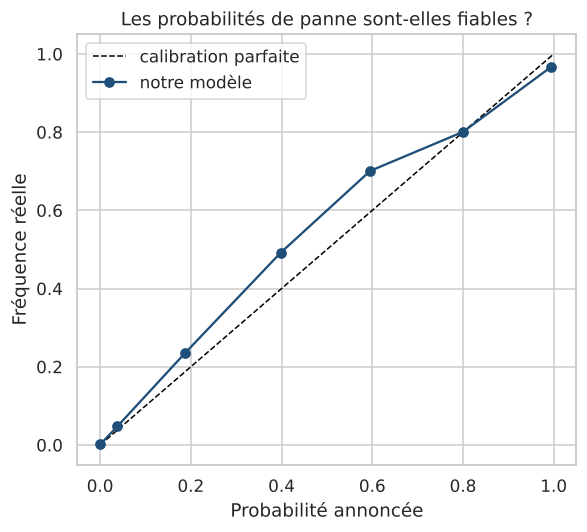

In [4]:
val["p_panne"] = proba_panne(val["rul_predite"], val["rul_basse"])
val["panne_30j"] = val["RUL"] <= DELAI

tranches = pd.cut(val["p_panne"], [-0.001, 0.01, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0])
calibration = val.groupby(tranches, observed=True).agg(
    vols=("panne_30j", "size"),
    proba_annoncee=("p_panne", "mean"),
    frequence_reelle=("panne_30j", "mean"),
)
display(calibration.round(3))
print(
    f"Total : {val['p_panne'].sum():.0f} pannes attendues par le modèle, {val['panne_30j'].sum()} réelles"
)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color="black", ls="--", lw=1, label="calibration parfaite")
ax.plot(
    calibration["proba_annoncee"],
    calibration["frequence_reelle"],
    marker="o",
    color="#1f4e79",
    label="notre modèle",
)
ax.set(
    xlabel="Probabilité annoncée",
    ylabel="Fréquence réelle",
    title="Les probabilités de panne sont-elles fiables ?",
)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "16_calibration_probas.png")
plt.show()

> **Lecture :** la courbe suit bien la diagonale. Au total, le modèle attend 3 024 pannes dans les 30 jours pour 3 100 réelles, soit un écart de 2,5 %. Dans la zone intermédiaire (30-70 %), il **sous-estime un peu** : quand il annonce 40 %, c'est plutôt 50 %. C'est encore le biais « trop tard » du notebook 02. Conséquence à surveiller : la politique pilotée pourrait commander un peu tard, et subir quelques ruptures. La simulation le dira.

---
## Étape 4 · De probabilités moteur par moteur à un seuil de commande R(t)

C'est le cœur de la méthode d'Embraer. Un jour donné, la flotte a 100 moteurs, chacun avec sa probabilité d'être déposé avant la prochaine livraison. **Combien de modules faut-il avoir pour être couvert avec, disons, 95 % de confiance ?**

**L'exemple du papier [8]** : 3 moteurs, avec des probabilités de 80 %, 50 % et 10 %.
- 0 dépose : 0,2 × 0,5 × 0,9 = **9 %**
- 3 déposes : 0,8 × 0,5 × 0,1 = **4 %**
- 1 dépose : (A seul) 0,8 × 0,5 × 0,9 + (B seul) 0,2 × 0,5 × 0,9 + (C seul) 0,2 × 0,5 × 0,1 = **46 %**
- 2 déposes : le reste, **41 %**

Probabilités cumulées : 9 %, 55 %, **96 %**, 100 %. Avec **2 modules**, on est couvert à 96 % ≥ 95 %. Donc **R(t) = 2**.

Avec 100 moteurs, on ne peut pas énumérer toutes les combinaisons à la main (2¹⁰⁰ !). On ajoute les moteurs **un par un** : si on connaît la loi du nombre de déposes pour les k premiers moteurs, alors pour le (k+1)e, de probabilité p :
- « n déposes » = (n déposes avant ET il ne casse pas) + (n − 1 déposes avant ET il casse).

C'est exactement ce que fait la boucle ci-dessous. En maths, cette loi s'appelle la **loi de Poisson-binomiale**.

In [5]:
def seuil_commande(probas, niveau):
    """Plus petit nombre de modules n tel que P(nombre de déposes <= n) >= niveau."""
    probas = probas[probas > 1e-6]  # les moteurs à probabilité ~0 ne changent rien : on les saute
    loi = np.zeros(len(probas) + 1)  # loi[k] = P(k déposes), tableau créé une seule fois
    loi[0] = 1.0  # avant d'ajouter un moteur : 0 dépose avec probabilité 1
    for k, p in enumerate(probas, start=1):  # on ajoute les moteurs un par un
        # k déposes = (k déposes et ce moteur tient) + (k-1 déposes et ce moteur casse)
        loi[1 : k + 1] = loi[1 : k + 1] * (1 - p) + loi[:k] * p
        loi[0] *= 1 - p
    return int(np.searchsorted(np.cumsum(loi), niveau - 1e-12))


# ✅ Vérification sur l'exemple du papier
assert seuil_commande(np.array([0.8, 0.5, 0.1]), 0.95) == 2
assert seuil_commande(np.array([0.8, 0.5, 0.1]), 0.50) == 1  # 55 % >= 50 % dès 1 module
print("OK ✅ on retrouve R(t) = 2 de l'exemple d'Embraer")

OK ✅ on retrouve R(t) = 2 de l'exemple d'Embraer


---
## Étape 5 · La politique classique [R, Q]

Sans modèle, on ne connaît que la **consommation moyenne** : 100 moteurs qui vivent en moyenne 206 vols, soit 100 / 206 ≈ 0,49 dépose par jour.

**Combien commander à chaque fois (Q) ?** C'est la **quantité économique de commande** (formule de Wilson / EOQ, utilisée dans [8]). Elle équilibre deux forces :
- commander souvent et peu coûte cher en frais fixes K ;
- commander rarement et beaucoup coûte cher en stockage H.

> Q = √( 2 · D · K · (P + H) / (P · H) )

**À quel stock déclencher (R) ?** Pendant les 30 jours de délai, on attend en moyenne 0,49 × 30 ≈ 14,5 déposes. Le nombre réel varie : on le modélise par une **loi de Poisson**, la loi des événements rares et indépendants. R est le nombre de déposes qu'on ne dépassera pas avec 95 % de confiance (`poisson.ppf`).

Les **deux politiques utilisent le même Q**. Seul le seuil diffère : fixe pour l'une, recalculé chaque jour pour l'autre. Exactement comme dans [8].

In [6]:
durees_vie = val.groupby("unit")["cycle"].max()
DEMANDE_JOUR = N_MOTEURS / durees_vie.mean()
D, K, H, P = DEMANDE_JOUR, COUT_COMMANDE, COUT_POSSESSION, COUT_RUPTURE  # notations de la formule
Q = int(round(np.sqrt(2 * D * K * (P + H) / (P * H))))

NIVEAUX = [0.80, 0.90, 0.95, 0.99]
R_CLASSIQUE = {n: int(poisson.ppf(n, DEMANDE_JOUR * DELAI)) for n in NIVEAUX}

print(f"Demande moyenne : {DEMANDE_JOUR:.3f} dépose par jour, soit {DEMANDE_JOUR * 365:.0f} par an")
print(f"Quantité économique de commande Q = {Q} modules")
print("Seuil fixe R selon le taux de service :", R_CLASSIQUE)

Demande moyenne : 0.485 dépose par jour, soit 177 par an
Quantité économique de commande Q = 6 modules
Seuil fixe R selon le taux de service : {0.8: 18, 0.9: 20, 0.95: 21, 0.99: 24}


---
## Étape 6 · Le simulateur de flotte

Chaque jour, dans cet ordre :
1. **Livraisons** : les commandes passées il y a 30 jours arrivent (Q modules chacune). On sert d'abord les moteurs en attente, dans l'ordre d'arrivée.
2. **Vols** : chaque moteur en service vole. S'il atteint sa fin de vie, on le dépose. On pose un module si le stock en a un ; sinon, le moteur part en attente (rupture).
3. **Décision de commande** : on calcule la **position de stock** = modules en main + en route − dus aux moteurs en attente. Si elle est ≤ au seuil (R fixe, ou R(t) du jour), on commande Q modules.
4. **Coûts du jour** : possession (H × modules en main) et rupture (P × moteurs en attente).

**Trois choix de conception à connaître :**
- **Tirages communs.** Les deux politiques voient exactement les mêmes moteurs, avec les mêmes vies, dans le même ordre (même `graine`). La différence de coût vient donc **uniquement** de la politique, pas du hasard. C'est la méthode des « nombres aléatoires communs ».
- **Âges de départ au hasard.** Si tous les moteurs démarraient neufs le jour 1, ils tomberaient en panne en même temps. On tire un âge au hasard pour chacun : la flotte est « mélangée », comme une vraie flotte.
- **Une année de chauffe.** Les 365 premiers jours ne sont pas comptés, le temps que la simulation oublie son point de départ artificiel.

In [7]:
# --- Tables de consultation : pour chaque moteur du train et chaque âge, sa prédiction ---
unites = np.sort(val["unit"].unique())
VIES = durees_vie.reindex(unites).values
ligne = val["unit"].map({u: i for i, u in enumerate(unites)}).values
TAB_PRED = np.full((len(unites), VIES.max() + 1), np.nan)
TAB_PRED[ligne, val["cycle"]] = val["rul_predite"]
TAB_BASSE = np.full_like(TAB_PRED, np.nan)
TAB_BASSE[ligne, val["cycle"]] = val["rul_basse"]


def simuler(politique, niveau, graine, jours=3650, chauffe=365, journal=False):
    rng = np.random.default_rng(graine)
    # Tirages communs aux deux politiques : la suite des "vies" de chaque position, et les âges de départ
    suites = rng.integers(0, len(VIES), size=(N_MOTEURS, 400))
    rang = np.zeros(N_MOTEURS, dtype=int)
    vie = suites[:, 0].copy()  # quelle trajectoire suit chaque moteur
    age = np.array([rng.integers(1, VIES[j] + 1) for j in vie])  # âge de départ au hasard

    R_fixe = R_CLASSIQUE[niveau]
    stock = R_fixe + Q  # même stock de départ pour les deux politiques
    commandes = []  # dates d'arrivée des commandes en cours
    attente = []  # moteurs déposés qui attendent un module (file d'attente)
    en_attente = np.zeros(N_MOTEURS, dtype=bool)
    couts = dict(commande=0.0, possession=0.0, rupture=0.0)
    modules_achetes = deposes = deposes_servies = jours_immobilises = 0
    historique = []

    def poser_module(m):  # nouvelle vie pour le moteur m
        rang[m] += 1
        vie[m] = suites[m, rang[m]]
        age[m] = 1

    for t in range(jours):
        compte = t >= chauffe

        # 1) Livraisons : chaque commande arrivée apporte Q modules ; on sert d'abord la file d'attente
        arrivees = commandes.count(t)
        commandes = [d for d in commandes if d != t]
        stock += Q * arrivees
        while stock > 0 and attente:
            m = attente.pop(0)
            stock -= 1
            en_attente[m] = False
            poser_module(m)

        # 2) Vols : les moteurs en service volent ; ceux qui atteignent leur fin de vie sont déposés
        en_service = ~en_attente
        fin_de_vie = en_service & (age >= VIES[vie])
        for m in np.where(fin_de_vie)[0]:
            deposes += compte
            if stock > 0:
                stock -= 1
                poser_module(m)
                deposes_servies += compte
            else:
                en_attente[m] = True
                attente.append(m)  # rupture : le moteur attend
        age[en_service & ~fin_de_vie] += 1

        # 3) Décision de commande
        if politique == "classique":
            R = R_fixe
        else:
            vole = ~en_attente
            probas = proba_panne(TAB_PRED[vie[vole], age[vole]], TAB_BASSE[vie[vole], age[vole]])
            R = seuil_commande(probas, niveau)
        position = stock + Q * len(commandes) - len(attente)  # en main + en route - dus
        while position <= R:
            commandes.append(t + DELAI)
            position += Q
            if compte:
                couts["commande"] += COUT_COMMANDE
                modules_achetes += Q

        # 4) Coûts du jour
        if compte:
            couts["possession"] += COUT_POSSESSION * stock
            couts["rupture"] += COUT_RUPTURE * len(attente)
            jours_immobilises += len(attente)
        if journal:
            historique.append(
                (t, stock, Q * len(commandes) + stock - len(attente), R, len(attente))
            )

    annees = (jours - chauffe) / 365
    resultat = {k: v / annees for k, v in couts.items()}
    resultat["total"] = sum(resultat.values())
    resultat.update(
        stock_moyen=couts["possession"] / COUT_POSSESSION / (jours - chauffe),
        taux_service=deposes_servies / max(deposes, 1),
        jours_immobilises_an=jours_immobilises / annees,
        deposes_an=deposes / annees,
        modules_achetes_an=modules_achetes / annees,
    )
    if journal:
        return resultat, pd.DataFrame(
            historique, columns=["jour", "stock", "position", "seuil", "en_attente"]
        )
    return resultat

In [8]:
# ✅ Vérifications du simulateur sur une simulation de chaque politique
for pol in ["classique", "pilotee"]:
    r = simuler(pol, 0.95, graine=0)
    # Sur 9 ans, on doit acheter à peu près autant de modules qu'on en consomme (bilan des pièces)
    assert abs(r["modules_achetes_an"] - r["deposes_an"]) / r["deposes_an"] < 0.05, r
    # Une flotte de 100 moteurs de vie moyenne ~206 vols dépose ~100/206*365 ≈ 177 modules par an
    assert abs(r["deposes_an"] - DEMANDE_JOUR * 365) / (DEMANDE_JOUR * 365) < 0.05
    assert 0 <= r["taux_service"] <= 1
    print(
        f"OK ✅ {pol:9s}: {r['deposes_an']:.0f} déposes/an, {r['modules_achetes_an']:.0f} modules achetés/an, "
        f"taux de service {r['taux_service']:.1%}"
    )

OK ✅ classique: 176 déposes/an, 176 modules achetés/an, taux de service 99.3%


OK ✅ pilotee  : 176 déposes/an, 175 modules achetés/an, taux de service 99.9%


---
## Étape 7 · Une simulation regardée de près

Avant les statistiques, on **regarde** ce qui se passe. Même flotte, mêmes moteurs, taux de service visé 95 %, deux ans après la chauffe.

**Comment lire le graphique :** la zone colorée, c'est ce qu'il y a **dans l'entrepôt**. Le seuil (en rouge) ne se compare pas à ce stock, mais à la **position** (en pointillés) : en entrepôt + en route. Quand la position passe sous le seuil, on commande Q = 6 modules, et la position remonte aussitôt de 6. L'entrepôt, lui, ne les reçoit que 30 jours plus tard.

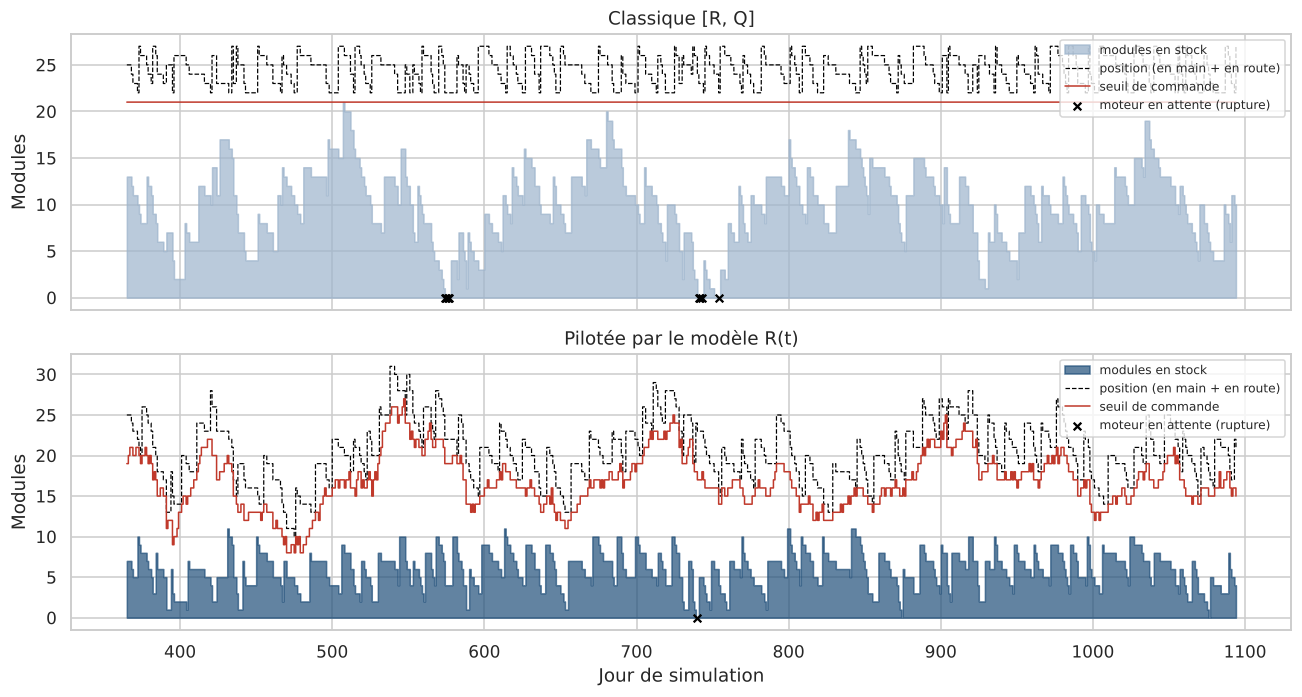

Stock moyen : classique 9.9 modules, pilotée 6.0 modules


In [9]:
res_c, jc = simuler("classique", 0.95, graine=0, journal=True)
res_p, jp = simuler("pilotee", 0.95, graine=0, journal=True)

fenetre = slice(365, 365 + 730)
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax, j, nom, coul in [
    (axes[0], jc, "Classique [R, Q]", "#9db4cc"),
    (axes[1], jp, "Pilotée par le modèle R(t)", "#1f4e79"),
]:
    d = j.iloc[fenetre]
    ax.fill_between(
        d["jour"], d["stock"], step="post", color=coul, alpha=0.7, label="modules en stock"
    )
    ax.step(
        d["jour"],
        d["position"],
        where="post",
        color="black",
        lw=0.8,
        ls="--",
        label="position (en main + en route)",
    )
    ax.step(d["jour"], d["seuil"], where="post", color="#c0392b", lw=1, label="seuil de commande")
    rup = d[d["en_attente"] > 0]
    ax.scatter(
        rup["jour"],
        np.zeros(len(rup)),
        color="black",
        marker="x",
        s=25,
        label="moteur en attente (rupture)",
    )
    ax.set(title=nom, ylabel="Modules")
    ax.legend(loc="upper right", fontsize=8)
axes[1].set_xlabel("Jour de simulation")
plt.tight_layout()
plt.savefig(FIG_DIR / "17_stock_deux_politiques.png")
plt.show()

print(
    f"Stock moyen : classique {res_c['stock_moyen']:.1f} modules, pilotée {res_p['stock_moyen']:.1f} modules"
)

> **Lecture :**
> - **En classique**, le seuil est une ligne plate. On recommande dès que la position touche ce niveau, que des moteurs soient près de leur fin de vie ou pas. Le stock en entrepôt reste haut « au cas où ».
> - **En pilotée**, le seuil **monte et descend** avec l'état réel de la flotte. Il monte quand plusieurs moteurs approchent de leur fin de vie, et il descend quand la flotte est en bonne santé. Les modules arrivent **quand on en a besoin** et dorment moins longtemps en entrepôt.

---
## Étape 8 · La comparaison complète

Une seule simulation peut avoir de la chance. On répète donc **10 fois** (10 graines, donc 10 flottes différentes), pour chacun des 4 taux de service et chacune des 2 politiques : 80 simulations de 10 ans. Comme les tirages sont communs, chaque paire classique/pilotée est comparée **sur la même flotte**.

In [10]:
resultats = pd.DataFrame(
    [
        {"niveau": niveau, "graine": graine, "politique": pol, **simuler(pol, niveau, graine)}
        for niveau in NIVEAUX
        for graine in range(10)
        for pol in ["classique", "pilotee"]
    ]
)

synthese = resultats.groupby(["niveau", "politique"]).agg(
    cout_total=("total", "mean"),
    commande=("commande", "mean"),
    possession=("possession", "mean"),
    rupture=("rupture", "mean"),
    stock_moyen=("stock_moyen", "mean"),
    taux_service=("taux_service", "mean"),
    jours_immobilises_an=("jours_immobilises_an", "mean"),
)
(synthese / [1000, 1000, 1000, 1000, 1, 0.01, 1]).round(1).rename(
    columns={
        "cout_total": "total (k€/an)",
        "commande": "commandes (k€/an)",
        "possession": "possession (k€/an)",
        "rupture": "ruptures (k€/an)",
        "stock_moyen": "stock moyen (modules)",
        "taux_service": "service atteint (%)",
        "jours_immobilises_an": "jours d'attente/an",
    }
)

total (k€/an)  commandes (k€/an)  possession (k€/an)  \
niveau politique                                                         
0.80   classique         1700.3              146.8               352.9   
       pilotee            565.7              146.9               241.6   
0.90   classique          951.9              147.0               450.4   
       pilotee            479.7              147.0               273.2   
0.95   classique          835.7              147.0               499.8   
       pilotee            468.7              147.0               298.4   
0.99   classique          819.8              147.0               649.4   
       pilotee            502.2              146.9               349.1   

                  ruptures (k€/an)  stock moyen (modules)  \
niveau politique                                            
0.80   classique            1200.6                    7.1   
       pilotee               177.2                    4.8   
0.90   classique             354.4                    9.0   
       pilotee                59.4                    5.5   
0.95   classique             188.9                   10.0   
       pilotee                23.3                    6.0   
0.99   classique              23.3                   13.0   
       pilotee                 6.1                    7.0   

                  service atteint (%)  jours d'attente/an  
niveau politique                                           
0.80   classique                 96.0                24.0  
       pilotee                   98.8                 3.5  
0.90   classique                 98.7                 7.1  
       pilotee                   99.6                 1.2  
0.95   classique                 99.3                 3.8  
       pilotee                   99.8                 0.5  
0.99   classique                 99.9                 0.5  
       pilotee                  100.0                 0.1

In [11]:
# Économie de la politique pilotée, mesurée paire par paire (même flotte, même graine)
paires = resultats.pivot_table(index=["niveau", "graine"], columns="politique", values="total")
paires["economie"] = paires["classique"] - paires["pilotee"]
gain = paires.groupby("niveau")["economie"].agg(["mean", "min", "max"])
gain["en %"] = 100 * gain["mean"] / paires.groupby("niveau")["classique"].mean()
gain["paires gagnées"] = paires.groupby("niveau")["economie"].apply(lambda e: f"{(e > 0).sum()}/10")
(gain[["mean", "min", "max"]] / 1000).round(0).join(
    gain[["en %", "paires gagnées"]].round(0)
).rename(
    columns={
        "mean": "économie moyenne (k€/an)",
        "min": "pire flotte (k€/an)",
        "max": "meilleure flotte (k€/an)",
    }
)

,économie moyenne (k€/an),pire flotte (k€/an),meilleure flotte (k€/an),en %,paires gagnées
niveau,,,,,
0.80,1135.0,718.0,1614.0,67.0,10/10
0.90,472.0,213.0,835.0,50.0,10/10
0.95,367.0,208.0,580.0,44.0,10/10
0.99,318.0,276.0,408.0,39.0,10/10


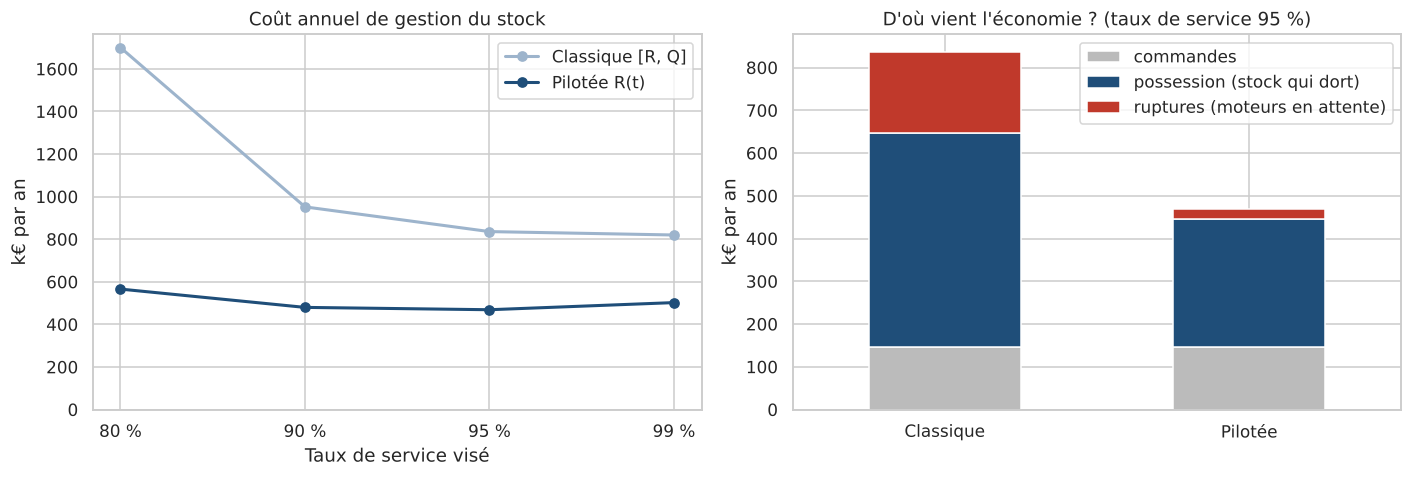

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# Gauche : coût total selon le taux de service
for pol, coul, nom in [
    ("classique", "#9db4cc", "Classique [R, Q]"),
    ("pilotee", "#1f4e79", "Pilotée R(t)"),
]:
    s = synthese.xs(pol, level="politique")
    axes[0].plot(
        [f"{int(n * 100)} %" for n in s.index],
        s["cout_total"] / 1000,
        marker="o",
        color=coul,
        lw=2,
        label=nom,
    )
axes[0].set(
    title="Coût annuel de gestion du stock",
    xlabel="Taux de service visé",
    ylabel="k€ par an",
    ylim=(0, None),
)
axes[0].legend()
# Droite : décomposition à 95 %
d = synthese.xs(0.95, level="niveau")[["commande", "possession", "rupture"]] / 1000
d.index = ["Classique", "Pilotée"]
d.plot(kind="bar", stacked=True, ax=axes[1], color=["#bbbbbb", "#1f4e79", "#c0392b"], rot=0)
axes[1].set(title="D'où vient l'économie ? (taux de service 95 %)", ylabel="k€ par an")
axes[1].legend(["commandes", "possession (stock qui dort)", "ruptures (moteurs en attente)"])
plt.tight_layout()
plt.savefig(FIG_DIR / "18_comparaison_politiques.png")
plt.show()

> **Lecture :**
> - **La politique pilotée est moins chère à tous les taux de service**, sur toutes les flottes simulées. C'est le résultat d'Embraer [8], reproduit sur nos moteurs avec nos prédictions.
> - **D'où vient l'économie ?** Surtout du **stock qui dort** : on garde en moyenne nettement moins de modules en entrepôt, parce qu'on les commande quand des moteurs en ont réellement besoin. Les coûts de commande sont identiques (même Q, même consommation).
> - **Les ruptures baissent aussi**, en moyenne à tous les taux de service, alors qu'elles restaient stables dans le papier. Notre modèle voit venir les « paquets » de déposes que la moyenne ne voit pas. Exemple à 95 % : environ 4 jours d'attente de moteurs par an en classique, contre moins d'un en pilotée.
> - **À 99 %, l'écart de ruptures se resserre** : la politique classique surstocke tellement qu'elle n'en a presque plus, et sur 2 flottes sur 10 elle en a même moins que la pilotée. Elle le paie très cher en possession (13 modules en stock en moyenne, contre 7).
> - **Le service atteint dépasse le service visé** dans les deux cas. C'est normal : le taux visé porte sur le risque de rupture pendant un délai, alors que le taux mesuré compte les déposes servies immédiatement. Ce sont deux définitions différentes, la seconde est plus indulgente.

In [13]:
a95 = synthese.xs(0.95, level="niveau")
stock_c, stock_p = a95.loc["classique", "stock_moyen"], a95.loc["pilotee", "stock_moyen"]
print("Au taux de service de 95 % :")
print(
    f"  coût de gestion du stock : {a95.loc['classique', 'cout_total'] / 1e3:,.0f} k€/an -> {a95.loc['pilotee', 'cout_total'] / 1e3:,.0f} k€/an "
    f"({100 * (1 - a95.loc['pilotee', 'cout_total'] / a95.loc['classique', 'cout_total']):.0f} %)"
)
print(
    f"  stock moyen : {stock_c:.1f} -> {stock_p:.1f} modules, soit {(stock_c - stock_p) * PRIX / 1e6:.1f} M€ de capital libéré"
)
print(
    f"  jours d'attente de moteurs : {a95.loc['classique', 'jours_immobilises_an']:.1f} -> {a95.loc['pilotee', 'jours_immobilises_an']:.1f} par an"
)

Au taux de service de 95 % :
  coût de gestion du stock : 836 k€/an -> 469 k€/an (44 %)
  stock moyen : 10.0 -> 6.0 modules, soit 1.0 M€ de capital libéré
  jours d'attente de moteurs : 3.8 -> 0.5 par an


---
## Étape 9 · Export pour Power BI

- `fact_stock_politiques.csv` : une ligne par (taux de service, politique), avec les coûts, le stock moyen et le service atteint. C'est le cœur d'une page « business case ».
- `fact_stock_journal.csv` : l'évolution jour par jour du stock et du seuil sur deux ans (simulation de l'étape 7), pour une courbe dans Power BI.

In [14]:
export = synthese.reset_index()
export["politique"] = export["politique"].map(
    {"classique": "Classique [R, Q]", "pilotee": "Pilotée par le modèle"}
)
export["taux_service_vise"] = (export["niveau"] * 100).astype(int)
export = export.drop(columns="niveau").round(2)
export.to_csv(POWERBI_DIR / "fact_stock_politiques.csv", index=False, sep=";", decimal=",")

journal = pd.concat(
    [
        jc.iloc[fenetre].assign(politique="Classique [R, Q]"),
        jp.iloc[fenetre].assign(politique="Pilotée par le modèle"),
    ]
)
journal.to_csv(POWERBI_DIR / "fact_stock_journal.csv", index=False, sep=";", decimal=",")
resultats.to_csv(PROCESSED_DIR / "simulation_stock_FD001.csv", index=False)
export

,politique,cout_total,commande,possession,rupture,stock_moyen,taux_service,jours_immobilises_an,taux_service_vise
0,"Classique [R, Q]",1700331.05,146833.33,352942.16,1200555.56,7.06,0.96,24.01,80
1,Pilotée par le modèle,565683.41,146888.89,241572.30,177222.22,4.83,0.99,3.54,80
2,"Classique [R, Q]",951884.32,147000.00,450439.88,354444.44,9.01,0.99,7.09,90
3,Pilotée par le modèle,479687.98,147000.00,273243.53,59444.44,5.46,1.00,1.19,90
4,"Classique [R, Q]",835736.68,147000.00,499847.79,188888.89,10.00,0.99,3.78,95
5,Pilotée par le modèle,468697.11,147000.00,298363.77,23333.33,5.97,1.00,0.47,95
6,"Classique [R, Q]",819774.73,147000.00,649441.40,23333.33,12.99,1.00,0.47,99
7,Pilotée par le modèle,502189.50,146944.44,349133.94,6111.11,6.98,1.00,0.12,99


## Limites à connaître (et à dire)

- **Les coûts sont des hypothèses.** L'ordre de grandeur de l'économie dépend du prix des modules, du taux de possession et du coût d'un AOG. Le notebook 05 testera la robustesse du résultat quand on les fait varier.
- **1 cycle = 1 jour** est une simplification. Un moyen-courrier fait plusieurs vols par jour, mais la logique de la comparaison ne change pas.
- **Une seule pièce, non réparable, un seul entrepôt**, comme dans [8]. En réalité, un module déposé part en réparation et revient : c'est un « stock tournant ». C'est une extension naturelle du modèle.
- **Les « nouvelles vies » sont tirées parmi 100 trajectoires simulées par la NASA.** La flotte simulée réutilise ces 100 moteurs.

## Synthèse pour le décideur

1. **Utiliser les prédictions de panne pour piloter les commandes coûte moins cher que la gestion de stock classique, à tous les taux de service testés et sur toutes les flottes simulées.**
2. **Au taux de service de 95 %, le coût de gestion du stock baisse d'environ 44 %** (de 836 à 469 k€ par an, sous nos hypothèses). L'économie vient surtout du stock qui dort : 6 modules en moyenne au lieu de 10, soit environ **1 M€ de capital libéré**. Il y a aussi moins de moteurs en attente de pièce.
3. **La méthode est simple à expliquer** : chaque jour, on additionne les risques de panne de la flotte avant la prochaine livraison, et on commande si le stock ne couvre pas ce risque.
4. **Elle repose sur des probabilités fiables**, et on l'a vérifié (calibration). La légère sous-estimation des risques intermédiaires n'a pas créé de ruptures supplémentaires dans la simulation, mais c'est le premier point à surveiller sur des données réelles.

**Étape suivante (notebook 05) :** le business case complet, avec la comparaison à la maintenance à intervalle fixe et la sensibilité aux hypothèses de coûts.